# Visualize labels

Colorizes the AI4Mars MSL labels in MCAM `labels/<split>` and overlays them on the matching images in `images`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from PIL import Image

DATA_DIR = Path("../../dataset/ai4mars-dataset-merged-0.6/msl/mcam")
SPLIT = "train"

# ai4mars-dataset-merged-0.6/label_keys.json: 0 is unlabeled, and soil/bedrock/sand/big rock are 1-4. Doesnt match docs - 255 never appears - looks shifted up by one
CLASSES = {
    0: ("unlabeled", (0, 0, 0)),
    1: ("soil", (10, 128, 10)),
    2: ("bedrock", (230, 51, 51)),
    3: ("sand", (242, 217, 77)),
    4: ("big rock", (51, 102, 230)),
}
UNLABELED = 0

image_dir = DATA_DIR / "images"
label_dir = DATA_DIR / "labels" / SPLIT


def label_path(image_path):
    return next(label_dir.glob(f"{image_path.stem}_*.png"))


def colorize(label):
    rgb = np.zeros((*label.shape, 3), dtype=np.uint8)
    for k, (mat, color) in CLASSES.items():
        rgb[label == k] = color
    return rgb


image_paths = sorted(image_dir.glob("*.JPG"))
print(f"{len(image_paths)} images in {image_dir}")

9099 images in ../../dataset/ai4mars-dataset-merged-0.6/msl/mcam/images


## Image / label / overlay

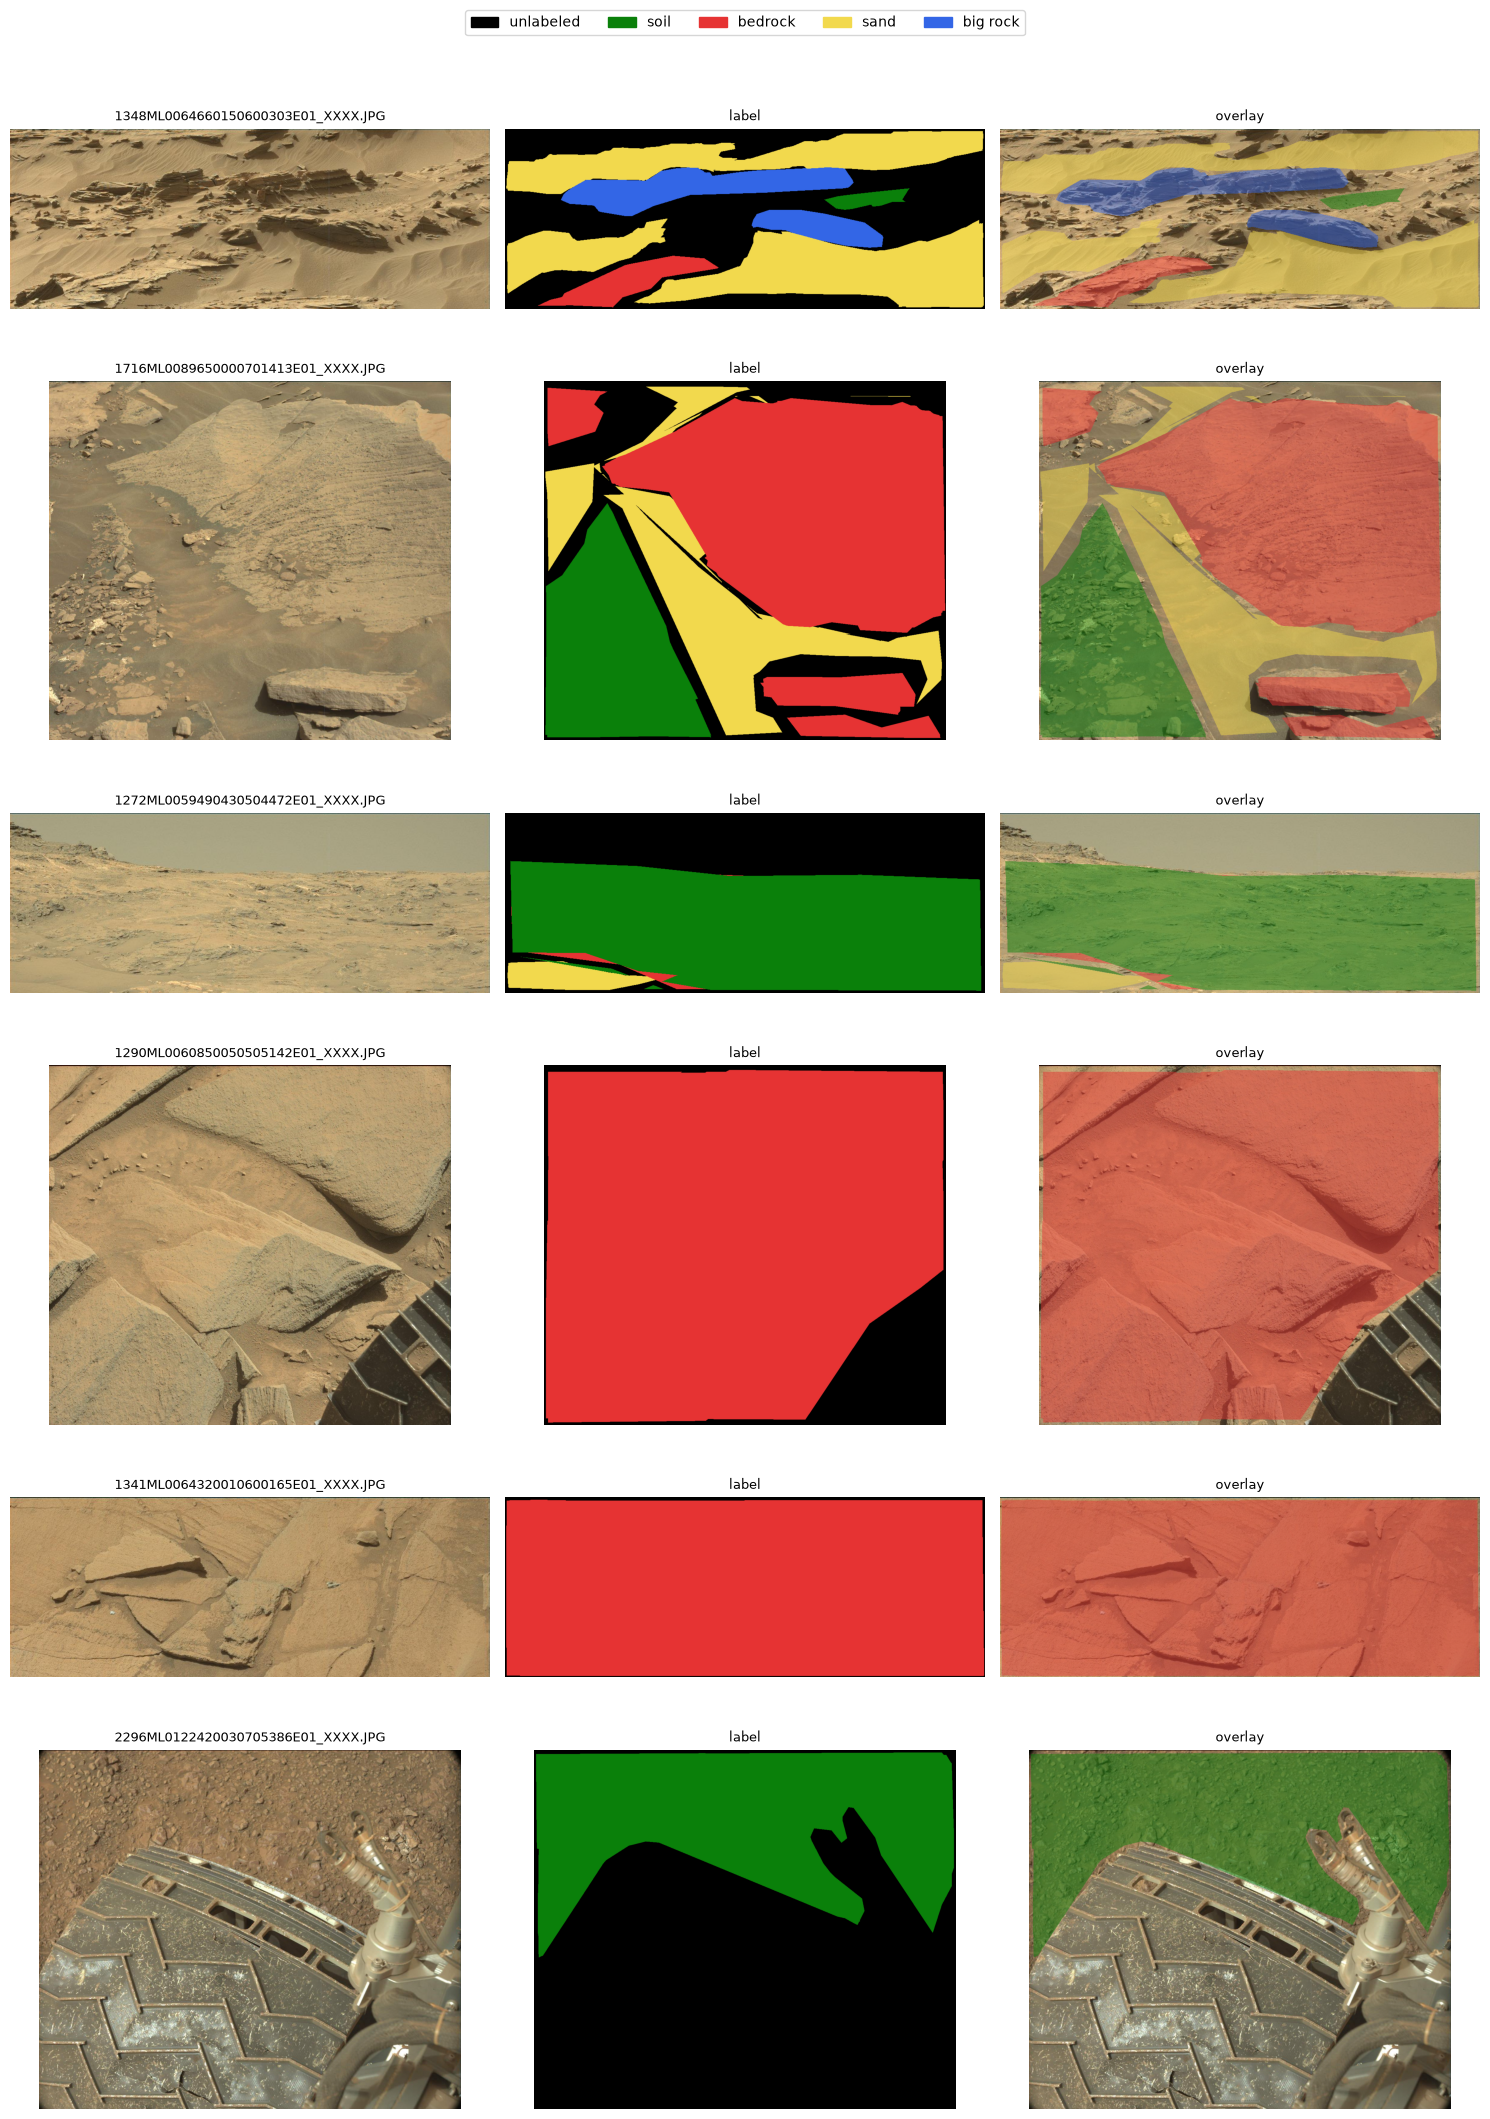

In [5]:
N = 6
ALPHA = 0.5
rng = np.random.default_rng(8)
sample = rng.choice(image_paths, size=min(N, len(image_paths)), replace=False)

fig, axes = plt.subplots(len(sample), 3, figsize=(15, 3.5 * len(sample)))
for row, img_path in zip(np.atleast_2d(axes), sample):
    image = np.array(Image.open(img_path).convert("RGB"))
    label = np.array(Image.open(label_path(img_path)))
    color = colorize(label)
    overlay = np.where((label == UNLABELED)[..., None], image, (1 - ALPHA) * image + ALPHA * color).astype(np.uint8)

    for ax, im, title in zip(row, [image, color, overlay], [img_path.name, "label", "overlay"]):
        ax.imshow(im)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

handles = [Patch(color=np.array(rgb) / 255, label=name) for name, rgb in CLASSES.values()]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.01))
plt.tight_layout()
plt.show()

## Class distribution

In [ ]:
counts = {k: 0 for k in CLASSES}
for img_path in image_paths:
    values, n = np.unique(np.array(Image.open(label_path(img_path))), return_counts=True)
    for v, k in zip(values, n):
        counts[int(v)] = counts.get(int(v), 0) + int(k)

total = sum(counts.values())
names = [CLASSES.get(k, (str(k), None))[0] for k in counts]
colors = [np.array(CLASSES.get(k, (None, (128, 128, 128)))[1]) / 255 for k in counts]
frac = [v / total for v in counts.values()]

plt.figure(figsize=(8, 4))
plt.bar(names, frac, color=colors)
plt.ylabel("fraction of pixels")
plt.title(f"Pixel class distribution ({SPLIT}, {len(image_paths)} labels)")
plt.show()

for name, f in zip(names, frac):
    print(f"{name:>18}: {f:.2%}")

Should use MCAM as well.

In [ ]:
img_path = image_dir / "1155ML0052230010501946E01_XXXX.JPG"
image = np.array(Image.open(img_path).convert("RGB"))
label = np.array(Image.open(label_path(img_path)))
color = colorize(label)
ALPHA = 0.5
overlay = np.where((label == UNLABELED)[..., None], image, (1 - ALPHA) * image + ALPHA * color).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, im, title in zip(axes, [image, overlay], ["Original Mars Image", "Semantic Segmentation Overlay"]):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")

# only bedrock (red) and sand (yellow) appear in this image
handles = [Patch(color=np.array(CLASSES[k][1]) / 255, label=CLASSES[k][0]) for k in (2, 3)]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 0.02))
plt.tight_layout()
fig.savefig("mars_overlay.png", dpi=300, bbox_inches="tight")
plt.show()


: 

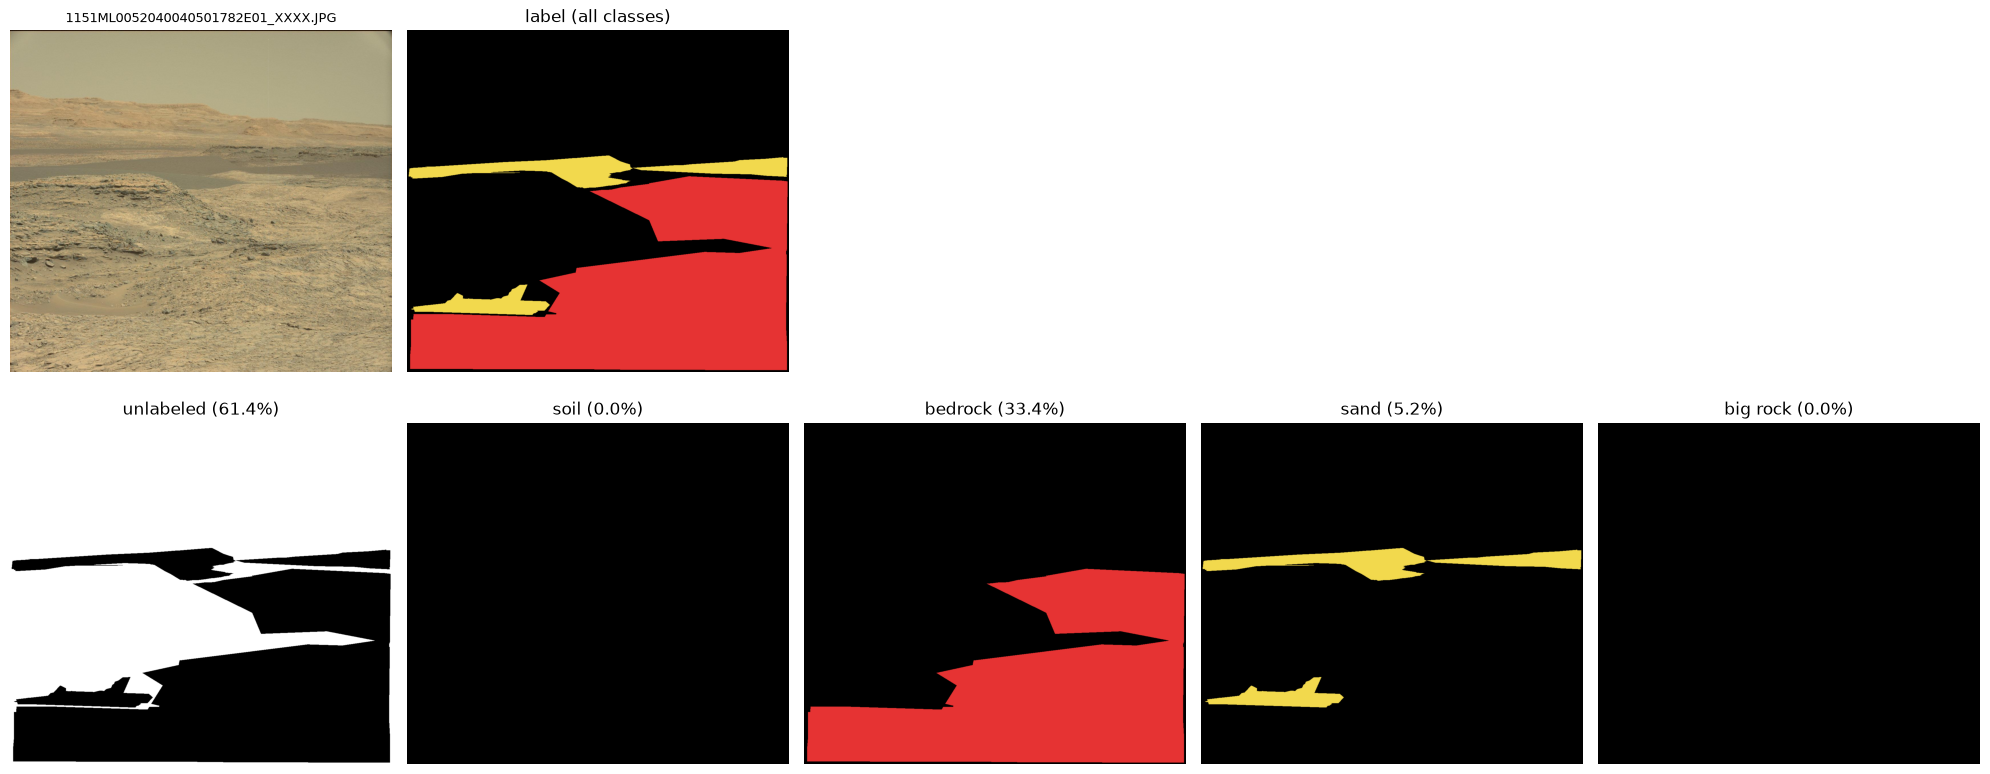

In [3]:
img_path = image_dir / "1151ML0052040040501782E01_XXXX.JPG"
image = np.array(Image.open(img_path).convert("RGB"))
label = np.array(Image.open(label_path(img_path)))

# top row: image and full label; bottom row: one mask per class
fig, axes = plt.subplots(2, len(CLASSES), figsize=(4 * len(CLASSES), 8))
for ax in axes.flat:
    ax.axis("off")

axes[0, 0].imshow(image)
axes[0, 0].set_title(img_path.name, fontsize=9)
axes[0, 1].imshow(colorize(label))
axes[0, 1].set_title("label (all classes)")

for ax, (k, (name, rgb)) in zip(axes[1], CLASSES.items()):
    mask = label == k
    # unlabeled's class color is black, so draw its mask in white to keep it visible on the black background
    mask_color = (255, 255, 255) if k == UNLABELED else rgb
    mask_rgb = np.zeros((*label.shape, 3), dtype=np.uint8)
    mask_rgb[mask] = mask_color
    ax.imshow(mask_rgb)
    ax.set_title(f"{name} ({mask.mean():.1%})")

plt.tight_layout()
plt.show()